# 03 — Analisis Univariat
### Milestone M3 (dinilai saat UTS) · Pertemuan 6 · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | Kelompok-EDA_AI01 |
| **Anggota** | Abdul Aziz Al Palembani, Fahri Mulyadi, Lukman Maruf, Nicha Amelia SRG |
| **Topik proyek** | Beban COVID-19 antarprovinsi di Indonesia, 1 Januari – 15 September 2022 |
| **Tanggal** | [TANGGAL] |

**Notebook ini mengisi:** dimensi **Analisis univariat** (20) dan sebagian **Kualitas visualisasi** (15) pada Rubrik M3.

**Pertanyaan payung:** Daerah seperti apa di Indonesia yang paling banyak terkena COVID-19 pada 2022 (1 Januari sampai 15 September)?

Satu variabel pada satu waktu: bentuk distribusi, sebaran, outlier, dan artinya bagi pertanyaan kami. Notebook ini menjawab **Pertanyaan 1** (provinsi paling banyak / paling sedikit) dan **Pertanyaan 3** (pulau paling banyak), menyiapkan variabel untuk **Pertanyaan 2 dan 4** di `04_multivariate.ipynb`, dan menghasilkan **statistik acuan Python** untuk dibandingkan dengan workflow KNIME (M4).

**Kesinambungan dengan notebook lain.** Data yang dibaca adalah keluaran `02_cleaning.ipynb` (`covid_provinsi_bersih.csv`). Tabel provinsi dan pulau yang disusun di sini **diuji sama persis** dengan keluaran M1 (`00_analisis_awal_m1.ipynb`: `covid_2022_provinsi.csv` dan `covid_2022_pulau.csv`); bila ada yang berbeda, notebook berhenti dengan `assert`.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**.

In [1]:
# Notebook ini berada di notebooks/. Semua path di bawah relatif terhadap AKAR repositori,
# jadi pindah ke akar bila dijalankan dari folder notebooks/ (aman dijalankan dari mana pun).
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
DATA, SOROT, REDUP = '#0E7490', '#C2410C', '#5B6672'

PROCESSED = 'data/processed'
FIGURES   = 'reports/figures'
REPORTS   = 'reports'
os.makedirs(FIGURES, exist_ok=True)

# Jendela analisis proyek (pertanyaan payung)
W0, W1 = pd.Timestamp('2022-01-01'), pd.Timestamp('2022-09-15')

rb = lambda v: f'{v:,.0f}'.replace(',', '.')                # 1234567 -> 1.234.567 (gaya M1)
ribuan = FuncFormatter(lambda v, _: rb(v))

## 0. Muat data olahan dan batasi pada jendela analisis

`covid_provinsi_bersih.csv` memuat seluruh periode (2 Maret 2020 – 15 September 2022) karena keputusan di `02_cleaning.ipynb` adalah menyaring jendela pada tahap EDA. Penyaringan dilakukan di sini, dengan **angka acuan** yang harus cocok dengan M1 dan M2.

In [2]:
d = pd.read_csv(f'{PROCESSED}/covid_provinsi_bersih.csv', parse_dates=['date'])
print(f'Data olahan penuh : {len(d):,} baris x {d.shape[1]} kolom ({d.date.min().date()} .. {d.date.max().date()})')

w = d[d['date'].between(W0, W1)].copy()
print(f'Jendela 2022      : {len(w):,} baris, {w.location.nunique()} provinsi, {w.date.nunique()} tanggal')

# Angka acuan yang harus sama di M1, M2, notebook ini, dan workflow KNIME
assert len(w) == 34 * 258 - 2, 'seharusnya 34 provinsi x 258 hari - 2 baris 15 September yang tidak ada'
assert w['new_cases'].sum() == 2_134_660 and w['new_deaths'].sum() == 13_683
assert (w['new_cases'] >= 0).all() and (w['new_deaths'] >= 0).all()

# Kaitan dengan M2: baris bertanda kumulatif_janggal (Total Active negatif) tidak mempengaruhi new_cases/new_deaths
print('\nBaris kumulatif_janggal pada jendela:', int(w['kumulatif_janggal'].sum()),
      w.groupby('location')['kumulatif_janggal'].sum()[lambda s: s > 0].to_dict())

Data olahan penuh : 30,893 baris x 40 kolom (2020-03-01 .. 2022-09-15)
Jendela 2022      : 8,770 baris, 34 provinsi, 258 tanggal

Baris kumulatif_janggal pada jendela: 50 {'Aceh': 19, 'Bengkulu': 3, 'Jawa Timur': 28}


**Titik cek untuk workflow KNIME (M4).** Di KNIME, saring `date` antara 2022-01-01 dan 2022-09-15 (inklusif) pada `covid_provinsi_bersih.csv`. Hasilnya harus **8.770 baris**, jumlah `new_cases` **2.134.660**, jumlah `new_deaths` **13.683**. Bila angkanya berbeda, selisihnya ada di penyaringan, bukan di statistik.

## 0b. Variabel mana yang dianalisis, dan mengapa

Dua tingkat: **harian** (satu baris = provinsi × hari, n = 8.770) dan **provinsi** (satu baris = satu provinsi, n = 34). Pertanyaan kami antarprovinsi, jadi tingkat provinsi adalah satuan utama; tingkat harian dipakai untuk memahami bentuk data dan outlier.

| Variabel | Tipe | Mengapa relevan dengan pertanyaan kami |
|----------|------|----------------------------------------|
| `new_cases` (harian) | numerik, cacah | Bahan dasar semua ukuran kasus; bentuk sebarannya menentukan statistik yang pantas dipakai |
| `new_deaths` (harian) | numerik, cacah | Bahan dasar Pertanyaan 4 |
| `kasus` (jumlah `new_cases` per provinsi) | numerik, cacah | **Pertanyaan 1**: provinsi paling banyak / sedikit |
| `kasus_per_juta` (kasus ÷ penduduk × 1 juta) | numerik, rasio | Perbandingan adil provinsi besar dan kecil (ukuran Q1 di M1) |
| `kepadatan` (`population_density`) | numerik, rasio | **Pertanyaan 2** |
| `kematian_per_1000_kasus` | numerik, rasio | **Pertanyaan 4** |
| `pulau` (`island`) | kategorikal (7) | **Pertanyaan 3 dan 4** |
| `kelas_kasus`, `hari`, `special_status`, `time_zone` | kategorikal | Konteks: tingkat keparahan harian, ritme pelaporan mingguan, status wilayah |

## 0c. Tabel tingkat provinsi, diuji terhadap keluaran M1

Nama kolom mengikuti M1 (`kasus`, `kematian`, `penduduk`, `kepadatan`, …) supaya dapat dibaca silang. Tingkat kematian dihitung dari **jumlah agregat** (kematian ÷ kasus), bukan dari rata-rata kolom `case_fatality_rate`.

In [3]:
prov = (w.groupby('location')
          .agg(pulau=('island', 'first'), penduduk=('population', 'first'), kepadatan=('population_density', 'first'),
               hari_data=('date', 'nunique'), kasus=('new_cases', 'sum'), kematian=('new_deaths', 'sum'))
          .reset_index().rename(columns={'location': 'provinsi'}))
prov['kasus_per_juta']          = prov['kasus'] / prov['penduduk'] * 1_000_000
prov['kematian_per_juta']       = prov['kematian'] / prov['penduduk'] * 1_000_000
prov['kematian_per_1000_kasus'] = prov['kematian'] / prov['kasus'] * 1000
prov['kelompok_kepadatan']      = pd.qcut(prov['kepadatan'], 3, labels=['Jarang', 'Sedang', 'Padat'])

# --- Uji kesinambungan dengan M1 (00_analisis_awal_m1.ipynb) ---
m1 = pd.read_csv(f'{PROCESSED}/covid_2022_provinsi.csv')
c = prov.merge(m1, on='provinsi', suffixes=('', '_m1'), validate='1:1')
assert len(c) == 34
for k in ['pulau', 'penduduk', 'hari_data', 'kasus', 'kematian']:
    assert (c[k] == c[k + '_m1']).all(), f'{k} tidak sama dengan M1'
for k in ['kepadatan', 'kasus_per_juta', 'kematian_per_juta', 'kematian_per_1000_kasus']:
    assert np.allclose(c[k], c[k + '_m1'], atol=0.006), f'{k} tidak sama dengan M1'      # M1 membulatkan 2 desimal
assert (c['kelompok_kepadatan'].astype(str) == c['kelompok_kepadatan_m1'].astype(str)).all()
print('LOLOS: tabel provinsi sama dengan M1 (kasus, kematian, penduduk, kepadatan, per juta, kelompok kepadatan).')
print('Kelompok kepadatan:', prov['kelompok_kepadatan'].value_counts().sort_index().to_dict(), '(M1: Jarang 12, Sedang 11, Padat 11)')
prov.sort_values('kasus', ascending=False).head(3).round(1)

LOLOS: tabel provinsi sama dengan M1 (kasus, kematian, penduduk, kepadatan, per juta, kelompok kepadatan).
Kelompok kepadatan: {'Jarang': 12, 'Sedang': 11, 'Padat': 11} (M1: Jarang 12, Sedang 11, Padat 11)


,provinsi,pulau,penduduk,kepadatan,hari_data,kasus,kematian,kasus_per_juta,kematian_per_juta,kematian_per_1000_kasus,kelompok_kepadatan
4,DKI Jakarta,Jawa,10846145,16334.3,258,547214,1904,50452.4,175.5,3.5,Padat
8,Jawa Barat,Jawa,45161325,1276.6,258,464881,1181,10293.8,26.2,2.5,Padat
10,Jawa Timur,Jawa,40479023,846.8,258,201480,2019,4977.4,49.9,10.0,Padat


## 1. Variabel numerik

Untuk setiap variabel: ringkasan angka, lalu histogram berpasangan dengan boxplot pada sumbu x yang sama.

**Setelan statistik dibuat eksplisit** karena ini yang paling sering membuat angka berbeda antar-alat (lihat bagian 5): simpangan baku memakai `ddof=1` (sampel), kuartil memakai interpolasi linear, dan *skewness* dilaporkan dalam dua versi (pandas yang dikoreksi bias, dan SciPy yang tidak dikoreksi).

In [4]:
ARAH = {'orientation': 'horizontal'} if tuple(int(x) for x in mpl.__version__.split('.')[:2]) >= (3, 10) else {'vert': False}

def statistik(s):
    """Satu baris statistik deskriptif; n = n setelah dropna(). Setelan ditulis eksplisit."""
    s = pd.Series(s).dropna().astype(float)
    q1, q2, q3 = s.quantile([.25, .5, .75])                 # interpolasi linear (bawaan pandas/NumPy)
    iqr = q3 - q1
    z = (s - s.mean()).abs() / s.std(ddof=1)
    return {'n': len(s), 'mean': s.mean(), 'std_ddof1': s.std(ddof=1), 'std_ddof0': s.std(ddof=0),
            'min': s.min(), 'q1': q1, 'median': q2, 'q3': q3, 'max': s.max(), 'iqr': iqr,
            'skew_pandas': s.skew(), 'skew_scipy': stats.skew(s),
            'kurt_pandas': s.kurt(), 'kurt_scipy': stats.kurtosis(s),
            'batas_bawah_iqr': q1 - 1.5 * iqr, 'batas_atas_iqr': q3 + 1.5 * iqr,
            'outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            'outlier_z3': int((z > 3).sum()), 'persen_nol': (s == 0).mean() * 100}

def potret(seri, nama, satuan='', log=False, bins=32, simpan=None):
    """Histogram + boxplot pada satu sumbu x, plus ringkasan angka."""
    s = seri.dropna(); r = statistik(s)
    x = np.log10(s + 1) if log else s
    fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True, layout='constrained', gridspec_kw={'height_ratios': [3, 1]})
    ax[0].hist(x, bins=bins, color=DATA, edgecolor='white', linewidth=.6); ax[0].set_ylabel('frekuensi')
    ax[0].set_title(f'{nama} (n = {len(s):,})' + ('  - skala log10(x+1)' if log else ''))
    ax[1].boxplot(x, **ARAH, widths=.55, patch_artist=True, boxprops=dict(facecolor='#CFE8EF', edgecolor='#16202B'),
                  medianprops=dict(color=SOROT, linewidth=2),
                  flierprops=dict(marker='o', markersize=4, markerfacecolor=DATA, markeredgecolor='none', alpha=.6))
    ax[1].set_yticks([]); ax[1].set_xlabel((f'log10({nama} + 1)' if log else nama) + (f' ({satuan})' if satuan else ''))
    if simpan: plt.savefig(f'{FIGURES}/{simpan}', dpi=150)
    plt.show()
    print(f"n {r['n']:,}   mean {r['mean']:,.2f}   median {r['median']:,.2f}   selisih {r['mean'] - r['median']:+,.2f}")
    print(f"std (ddof=1) {r['std_ddof1']:,.2f}   IQR {r['iqr']:,.2f}   skewness {r['skew_pandas']:.2f} (pandas) / {r['skew_scipy']:.2f} (SciPy)")
    print(f"outlier batas IQR: {r['outlier_iqr']}  (batas {r['batas_bawah_iqr']:,.1f} .. {r['batas_atas_iqr']:,.1f})   outlier |z|>3: {r['outlier_z3']}   nol: {r['persen_nol']:.1f}%")
    return r

STAT = {}     # dikumpulkan lalu diekspor ke reports/p6_statistik_deskriptif.csv

### 1a. Kasus baru harian (provinsi × hari)

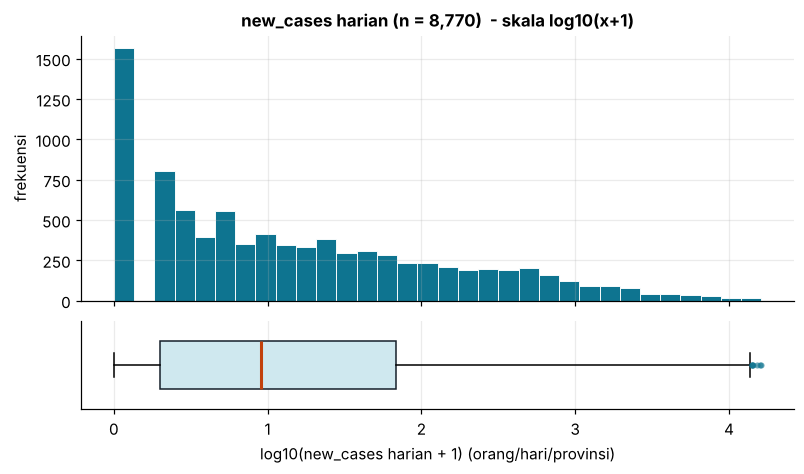

n 8,770   mean 243.40   median 8.00   selisih +235.40
std (ddof=1) 1,013.24   IQR 66.75   skewness 8.48 (pandas) / 8.48 (SciPy)
outlier batas IQR: 1516  (batas -99.1 .. 167.9)   outlier |z|>3: 141   nol: 17.8%


In [5]:
STAT['new_cases (harian)'] = potret(w['new_cases'], 'new_cases harian', 'orang/hari/provinsi', log=True, simpan='p6_kasus_harian.png')

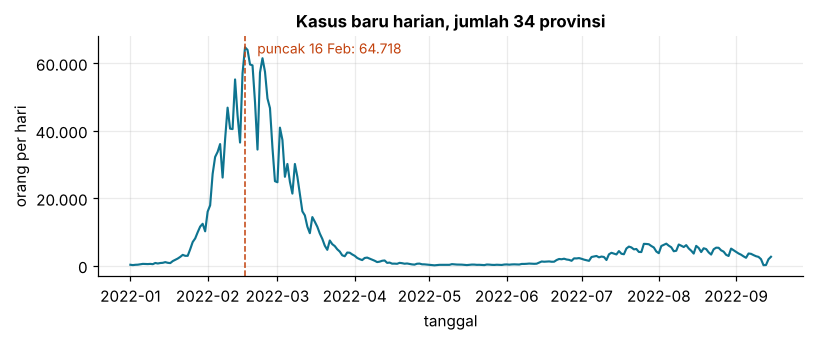

date
2022-01-01     4.2
2022-02-01    56.7
2022-03-01    21.0
2022-04-01     1.6
2022-05-01     0.4
2022-06-01     1.6
2022-07-01     5.6
2022-08-01     7.1
2022-09-01     1.8
Freq: MS


In [6]:
# Konteks bentuk waktu: jumlah 34 provinsi per hari, dan porsi tiap bulan
nas = w.groupby('date')['new_cases'].sum()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(nas.index, nas.values, color=DATA, lw=1.4); ax.axvline(nas.idxmax(), color=SOROT, lw=1, ls='--')
ax.annotate(f'puncak {nas.idxmax():%d %b}: {rb(nas.max())}', (nas.idxmax(), nas.max()), xytext=(8, -4), textcoords='offset points', color=SOROT, fontsize=9)
ax.set_title('Kasus baru harian, jumlah 34 provinsi'); ax.set_ylabel('orang per hari'); ax.set_xlabel('tanggal')
ax.yaxis.set_major_formatter(ribuan); plt.tight_layout(); plt.savefig(f'{FIGURES}/p6_kasus_harian_waktu.png', dpi=150); plt.show()
bulan = nas.resample('MS').sum()
print((bulan / bulan.sum() * 100).round(1).rename('% dari total jendela').to_string())

**Tafsiran 1a.** Distribusi harian **sangat menjulur ke kanan** (skewness 8,48): rata-rata 243,4 jauh di atas median 8 kasus/hari/provinsi, dan 17,8% baris bernilai 0. Pada skala asli histogram hampir tak terbaca, sehingga dipakai skala log10(x+1). Karena menjulur berat, **median** lebih mewakili hari "biasa" sebuah provinsi, sedangkan rata-rata ditarik oleh hari-hari puncak.
**Bukti dari gambar:** kurva waktu menunjukkan dua gelombang, puncak besar 16 Februari 2022 (64.718 kasus se-34 provinsi) dan gelombang lebih kecil sekitar Agustus. **Februari saja menyumbang ±57% seluruh kasus jendela** (daftar persen per bulan). Total kasus per provinsi pada pertanyaan kami karenanya terutama mencerminkan satu gelombang pendek, bukan tingkat rata-rata sepanjang 258 hari.

### 1b. Kematian baru harian

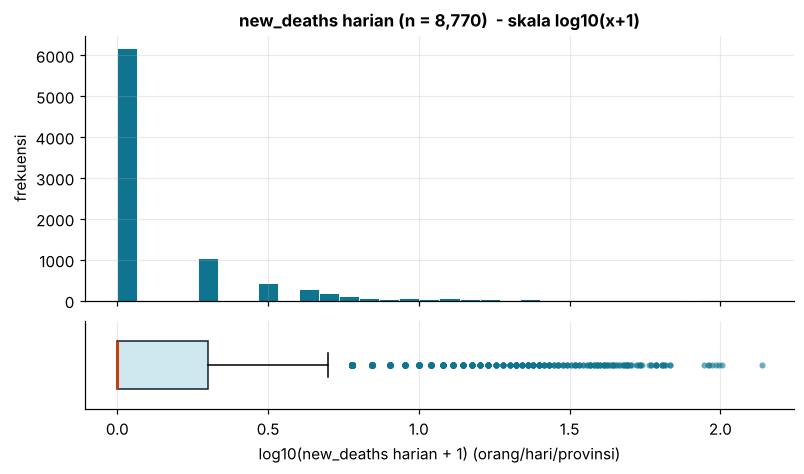

n 8,770   mean 1.56   median 0.00   selisih +1.56
std (ddof=1) 5.99   IQR 1.00   skewness 8.78 (pandas) / 8.77 (SciPy)
outlier batas IQR: 1131  (batas -1.5 .. 2.5)   outlier |z|>3: 152   nol: 70.4%


In [7]:
STAT['new_deaths (harian)'] = potret(w['new_deaths'], 'new_deaths harian', 'orang/hari/provinsi', log=True, simpan='p6_kematian_harian.png')

**Tafsiran 1b.** Lebih ekstrem daripada kasus: 70,4% baris bernilai 0, median 0, rata-rata 1,56, skewness 8,78. Data berupa cacah kecil dengan banyak nol (*zero-inflated*), sehingga rata-rata dan boxplot harian **tidak informatif** untuk kematian. Batas atas IQR hanya 2,5 (Q3 = 1), jadi setiap hari dengan 3 kematian atau lebih dihitung "outlier" (1.131 baris); angka ini lebih mencerminkan sempitnya IQR daripada kejadian luar biasa. Untuk Pertanyaan 4 kami memakai **jumlah agregat** per provinsi, bukan rata-rata harian.

### 1c. Total kasus per provinsi — Pertanyaan 1

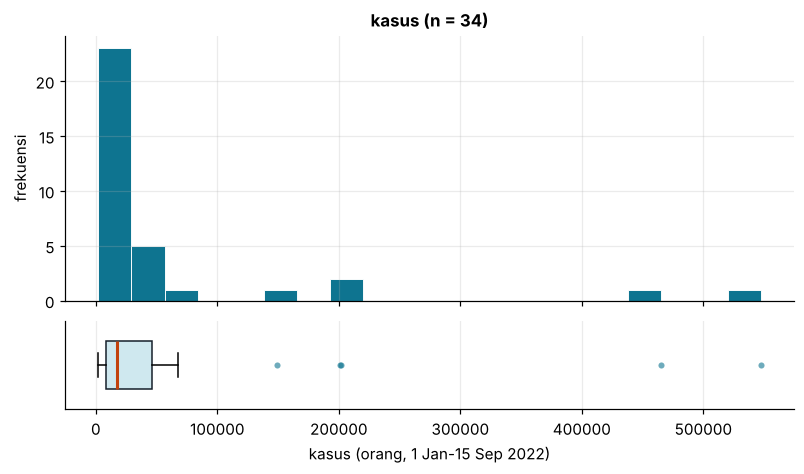

n 34   mean 62,784.12   median 17,096.50   selisih +45,687.62
std (ddof=1) 123,616.73   IQR 38,042.00   skewness 3.09 (pandas) / 2.95 (SciPy)
outlier batas IQR: 5  (batas -48,467.8 .. 103,700.2)   outlier |z|>3: 2   nol: 0.0%

   provinsi pulau  kasus
DKI Jakarta  Jawa 547214
 Jawa Barat  Jawa 464881
 Jawa Timur  Jawa 201480
     Banten  Jawa 201049
Jawa Tengah  Jawa 149494
         provinsi    pulau  kasus
        Gorontalo Sulawesi   2102
     Maluku Utara   Maluku   2490
   Sulawesi Barat Sulawesi   3233
           Maluku   Maluku   4140
Sulawesi Tenggara Sulawesi   5520

DKI Jakarta: 25.6% dari total;  3 teratas: 56.9%;  5 teratas: 73.3%


In [8]:
STAT['kasus (provinsi)'] = potret(prov['kasus'], 'kasus', 'orang, 1 Jan-15 Sep 2022', bins=20, simpan='p6_kasus_provinsi.png')
print()
print(prov.sort_values('kasus', ascending=False)[['provinsi', 'pulau', 'kasus']].head(5).to_string(index=False))
print(prov.sort_values('kasus')[['provinsi', 'pulau', 'kasus']].head(5).to_string(index=False))
bagi = prov['kasus'] / prov['kasus'].sum() * 100
print(f"\nDKI Jakarta: {bagi.max():.1f}% dari total;  3 teratas: {bagi.nlargest(3).sum():.1f}%;  5 teratas: {bagi.nlargest(5).sum():.1f}%")

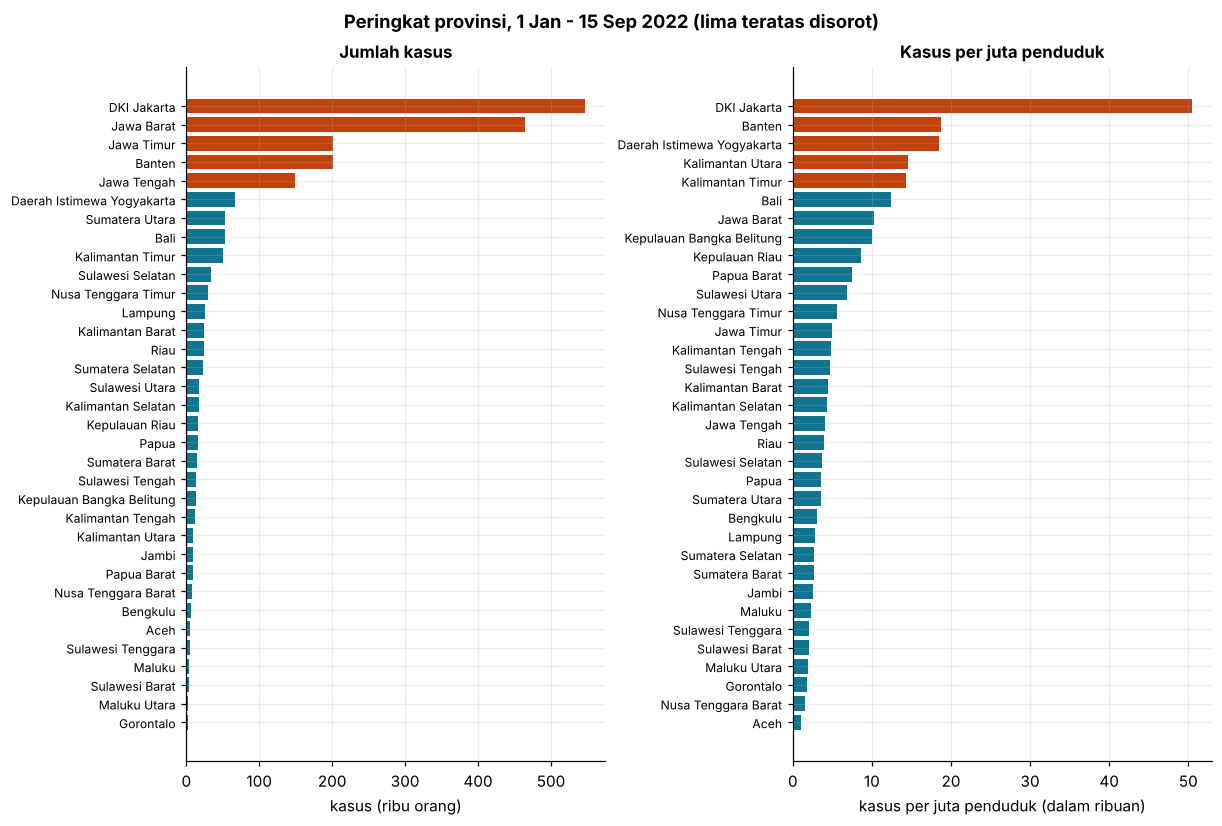

Per juta penduduk, 5 teratas : [('DKI Jakarta', '50.452'), ('Banten', '18.750'), ('Daerah Istimewa Yogyakarta', '18.538'), ('Kalimantan Utara', '14.616'), ('Kalimantan Timur', '14.269')]
Per juta penduduk, 5 terbawah: [('Aceh', '1.069'), ('Nusa Tenggara Barat', '1.601'), ('Gorontalo', '1.780'), ('Maluku Utara', '1.904'), ('Sulawesi Barat', '2.072')]


In [9]:
# Peringkat lengkap 34 provinsi: dua cara melihat "paling terkena" (jumlah kasus dan kasus per juta penduduk, ukuran M1)
o1, o2 = prov.sort_values('kasus'), prov.sort_values('kasus_per_juta')
fig, ax = plt.subplots(1, 2, figsize=(11, 7.4), layout='constrained')
ax[0].barh(o1['provinsi'], o1['kasus'] / 1e3, color=[SOROT if v >= o1['kasus'].nlargest(5).min() else DATA for v in o1['kasus']])
ax[0].set_xlabel('kasus (ribu orang)'); ax[0].set_title('Jumlah kasus')
ax[1].barh(o2['provinsi'], o2['kasus_per_juta'] / 1e3, color=[SOROT if v >= o2['kasus_per_juta'].nlargest(5).min() else DATA for v in o2['kasus_per_juta']])
ax[1].set_xlabel('kasus per juta penduduk (dalam ribuan)'); ax[1].set_title('Kasus per juta penduduk')
for a in ax: a.tick_params(axis='y', labelsize=8)
fig.suptitle('Peringkat provinsi, 1 Jan - 15 Sep 2022 (lima teratas disorot)', fontsize=12, fontweight='bold')
plt.savefig(f'{FIGURES}/p6_peringkat_provinsi.png', dpi=150); plt.show()
print('Per juta penduduk, 5 teratas :', [(r.provinsi, rb(r.kasus_per_juta)) for r in o2.tail(5).iloc[::-1].itertuples()])
print('Per juta penduduk, 5 terbawah:', [(r.provinsi, rb(r.kasus_per_juta)) for r in o2.head(5).itertuples()])

**Tafsiran 1c — jawaban sementara Pertanyaan 1.** Jumlah kasus antarprovinsi **sangat menjulur** (skewness 3,09): median 17.097 jauh di bawah rata-rata 62.784. **Paling banyak:** DKI Jakarta (547.214; 25,6% seluruh kasus), Jawa Barat (464.881), Jawa Timur (201.480), Banten (201.049), Jawa Tengah (149.494); lima teratas semuanya di Pulau Jawa dan menyumbang 73,3%. **Paling sedikit:** Gorontalo (2.102), Maluku Utara (2.490), Sulawesi Barat (3.233), Maluku (4.140), Sulawesi Tenggara (5.520).
Dengan ukuran **per juta penduduk** (ukuran Q1 di M1) Jakarta tetap teratas (50.452, sekitar 2,7 kali Banten di urutan kedua), tetapi **urutan bawah berubah**: terendah Aceh (1.069), NTB (1.601), Gorontalo (1.780). Jadi "paling sedikit terkena" bergantung pada ukuran: Aceh sedikit per kapita, tetapi bukan yang paling sedikit dalam jumlah. Pemusatan yang dipakai: **median** untuk ringkasan provinsi "biasa"; rata-rata tidak mewakili karena ditarik Jakarta.

### 1d. Kasus per juta penduduk

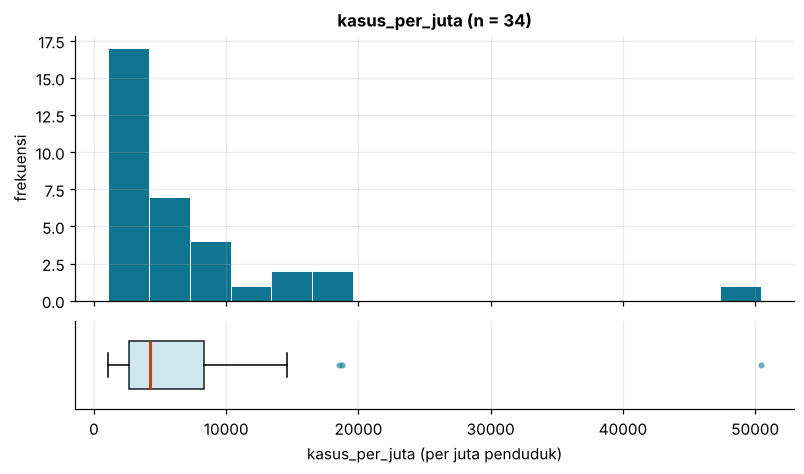

n 34   mean 7,249.52   median 4,233.22   selisih +3,016.30
std (ddof=1) 9,014.17   IQR 5,663.05   skewness 3.63 (pandas) / 3.47 (SciPy)
outlier batas IQR: 3  (batas -5,812.2 .. 16,840.0)   outlier |z|>3: 1   nol: 0.0%


In [10]:
STAT['kasus_per_juta (provinsi)'] = potret(prov['kasus_per_juta'], 'kasus_per_juta', 'per juta penduduk', bins=16, simpan='p6_kasus_per_juta.png')

**Tafsiran 1d.** Juga menjulur kanan (skewness 3,63): median 4.233 vs rata-rata 7.250. Tiga provinsi melewati batas IQR: DKI Jakarta, Banten, dan DI Yogyakarta. Nilai ini sah (hasil bagi kasus dan penduduk), bukan galat; Jakarta tetap dipertahankan dan pengaruhnya diuji di `04_multivariate.ipynb`.

### 1e. Kepadatan penduduk — variabel untuk Pertanyaan 2

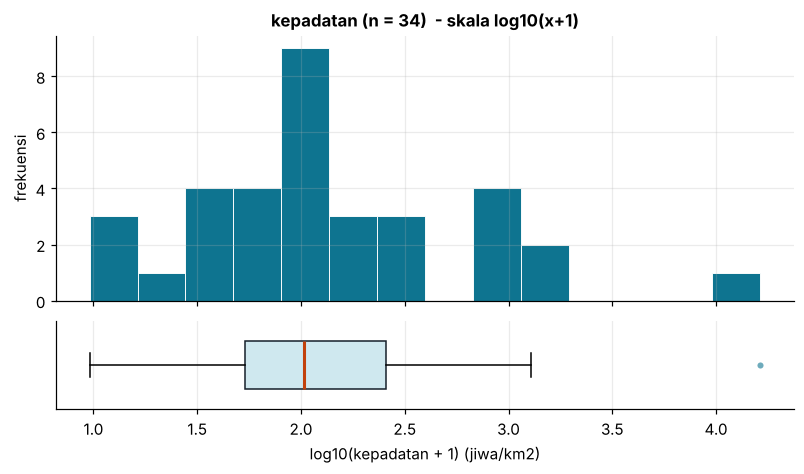

n 34   mean 744.17   median 102.11   selisih +642.06
std (ddof=1) 2,780.36   IQR 202.68   skewness 5.67 (pandas) / 5.41 (SciPy)
outlier batas IQR: 7  (batas -250.9 .. 559.9)   outlier |z|>3: 1   nol: 0.0%
                  provinsi  kepadatan
               DKI Jakarta    16334.3
                Jawa Barat     1276.6
Daerah Istimewa Yogyakarta     1158.9
                    Banten     1109.6
               Jawa Tengah     1108.6
        provinsi  kepadatan
Kalimantan Utara        8.6
     Papua Barat       11.1
           Papua       13.6


In [11]:
STAT['kepadatan (provinsi)'] = potret(prov['kepadatan'], 'kepadatan', 'jiwa/km2', log=True, bins=14, simpan='p6_kepadatan.png')
print(prov.sort_values('kepadatan', ascending=False)[['provinsi', 'kepadatan']].head(5).round(1).to_string(index=False))
print(prov.sort_values('kepadatan')[['provinsi', 'kepadatan']].head(3).round(1).to_string(index=False))

**Tafsiran 1e.** Kepadatan sangat menjulur (skewness 5,67): median 102 jiwa/km² vs rata-rata 744. DKI Jakarta (16.334 jiwa/km²) berjarak jauh dari provinsi berikutnya, dan tujuh provinsi melewati batas IQR. **Penting bagi Pertanyaan 2:** satu provinsi (Jakarta) punya pengaruh besar (*leverage*) pada statistik yang peka terhadap ekstrem, seperti korelasi Pearson; ini diuji dengan dan tanpa Jakarta di notebook 04. Kepadatan hanya punya 34 nilai (satu per provinsi), bukan ribuan. Itu juga alasan M1 memakai **tiga kelompok kepadatan menurut persentil** (Jarang 12, Sedang 11, Padat 11), bukan rata-rata.

### 1f. Kematian per 1.000 kasus — variabel untuk Pertanyaan 4

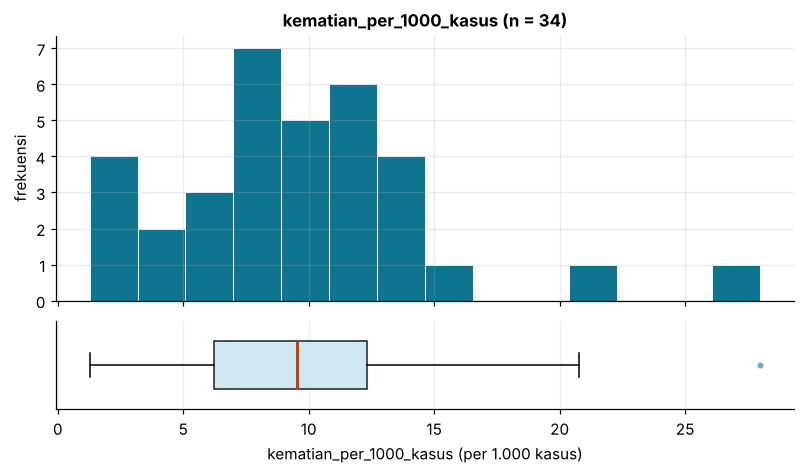

n 34   mean 9.54   median 9.52   selisih +0.02
std (ddof=1) 5.45   IQR 6.09   skewness 1.15 (pandas) / 1.10 (SciPy)
outlier batas IQR: 1  (batas -2.9 .. 21.5)   outlier |z|>3: 1   nol: 0.0%
      provinsi  kasus  kematian  kematian_per_1000_kasus
          Aceh   5608       157                     28.0
   Jawa Tengah 149494      3106                     20.8
Sumatera Barat  14767       218                     14.8
Sulawesi Barat   3233        47                     14.5
          Riau  23714       335                     14.1
        provinsi  kasus  kematian  kematian_per_1000_kasus
          Banten 201049       256                      1.3
           Papua  15553        20                      1.3
      Jawa Barat 464881      1181                      2.5
Kalimantan Barat  23934        69                      2.9
     Papua Barat   8510        28                      3.3

Gabungan 34 provinsi: 6.41 kematian per 1.000 kasus


In [12]:
STAT['kematian_per_1000_kasus (provinsi)'] = potret(prov['kematian_per_1000_kasus'], 'kematian_per_1000_kasus', 'per 1.000 kasus', bins=14, simpan='p6_kematian_per1000.png')
tampil = ['provinsi', 'kasus', 'kematian', 'kematian_per_1000_kasus']
print(prov.sort_values('kematian_per_1000_kasus', ascending=False)[tampil].head(5).round(1).to_string(index=False))
print(prov.sort_values('kematian_per_1000_kasus')[tampil].head(5).round(1).to_string(index=False))
print(f"\nGabungan 34 provinsi: {prov.kematian.sum() / prov.kasus.sum() * 1000:.2f} kematian per 1.000 kasus")

**Tafsiran 1f.** Jauh lebih simetris daripada variabel lain (skewness 1,15; rata-rata 9,54 ≈ median 9,52). Nilai **gabungan** seluruh Indonesia adalah **6,41 kematian per 1.000 kasus tercatat**, di bawah median provinsi karena provinsi besar berkasus banyak (Jakarta, Jawa Barat, Banten) berangka rendah dan mendominasi total. **Tertinggi:** Aceh (28,0; satu-satunya di luar batas IQR), Jawa Tengah (20,8), Sumatera Barat (14,8). **Terendah:** Banten dan Papua (1,3). Waspada: ini rasio terhadap kasus *yang terdeteksi*; provinsi berpengujian rendah hanya mendeteksi kasus berat sehingga rasionya tampak tinggi. Pada provinsi berkasus sedikit (Papua: 20 kematian dari 15.553 kasus) selisih beberapa kematian saja menggeser angka cukup jauh.

## 2. Keputusan tentang outlier

Outlier **tidak otomatis dibuang**. Periksa dulu apakah nilainya sah. Keputusan ini selaras dengan `02_cleaning.ipynb`: data yang janggal secara pencatatan ditandai (`kumulatif_janggal`), sedangkan nilai ekstrem yang sah dipertahankan.

In [13]:
tabel = pd.DataFrame(STAT).T[['n', 'outlier_iqr', 'outlier_z3', 'batas_bawah_iqr', 'batas_atas_iqr']]
tabel['persen_iqr'] = (tabel['outlier_iqr'] / tabel['n'] * 100).round(1)
print(tabel.round(1).to_string())

def tandai(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)
baris = []
for k in ['kasus', 'kasus_per_juta', 'kepadatan', 'kematian_per_1000_kasus']:
    m = tandai(prov[k]); prov['outlier_' + k] = m
    print(f'{k:26s}', prov.loc[m, 'provinsi'].tolist())
    baris += [{'variabel': k, 'provinsi': p, 'nilai': round(v, 2)} for p, v in zip(prov.loc[m, 'provinsi'], prov.loc[m, k])]
w['outlier_kasus_harian'] = tandai(w['new_cases'])
print('\nbaris harian outlier :', int(w['outlier_kasus_harian'].sum()), 'dari', len(w))
print(f"terjadi pada Feb-Mar 2022: {w.loc[w['outlier_kasus_harian'], 'date'].between('2022-02-01', '2022-03-31').mean() * 100:.0f}% dari outlier harian")
pd.DataFrame(baris).to_csv(f'{REPORTS}/p6_outlier_provinsi.csv', index=False)

                                         n  outlier_iqr  outlier_z3  batas_bawah_iqr  batas_atas_iqr  persen_iqr
new_cases (harian)                  8770.0       1516.0       141.0            -99.1           167.9        17.3
new_deaths (harian)                 8770.0       1131.0       152.0             -1.5             2.5        12.9
kasus (provinsi)                      34.0          5.0         2.0         -48467.8        103700.2        14.7
kasus_per_juta (provinsi)             34.0          3.0         1.0          -5812.2         16840.0         8.8
kepadatan (provinsi)                  34.0          7.0         1.0           -250.9           559.9        20.6
kematian_per_1000_kasus (provinsi)    34.0          1.0         1.0             -2.9            21.5         2.9
kasus                      ['Banten', 'DKI Jakarta', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
kasus_per_juta             ['Banten', 'DKI Jakarta', 'Daerah Istimewa Yogyakarta']
kepadatan                  ['B

| Variabel | Metode | Jumlah | Sah atau keliru? | Tindakan dan alasan |
|----------|--------|--------|------------------|---------------------|
| `new_cases` harian | IQR (1,5×) | 1.516 dari 8.770 (17,3%) | **Sah**: hari-hari gelombang Februari–Maret, bukan galat pencatatan | Dipertahankan; dilaporkan dengan median dan skala log |
| `new_cases` harian | \|z\| > 3 | 141 | Sah (sama) | Dipertahankan; z kurang cocok karena mean dan std ikut tertarik outlier |
| `new_deaths` harian | IQR | 1.131 (12,9%) | **Artefak IQR sempit** (Q3 = 1, batas atas 2,5) | Dipertahankan; tidak ditafsirkan sebagai kejadian luar biasa |
| `kasus` | IQR | 5 provinsi Jawa | **Sah**: provinsi berpenduduk besar | Dipertahankan; ditandai kolom penanda, tidak dibuang |
| `kasus_per_juta` | IQR | 3 (Jakarta, Banten, DI Yogyakarta) | Sah | Dipertahankan; pengaruh Jakarta diuji di notebook 04 |
| `kepadatan` | IQR | 7 provinsi | **Sah**: Jakarta 16.334 jiwa/km² benar adanya | Dipertahankan; uji dengan dan tanpa Jakarta |
| `kematian_per_1000_kasus` | IQR | 1 (Aceh, 28,0) | **Belum dapat dipastikan**: nyata, atau akibat pengujian rendah/pencatatan | Dipertahankan; keterbatasan, bukan "Aceh paling mematikan" |

Catatan: batas bawah IQR bernilai negatif pada variabel cacah/rasio yang tidak mungkin negatif; batas bawah praktisnya nol, itu konsekuensi aritmetika distribusi menjulur kanan, bukan temuan.

## 3. Variabel kategorikal

### 3a. Pulau — Pertanyaan 3 (diuji terhadap `covid_2022_pulau.csv` M1)

LOLOS: tabel pulau sama dengan M1.

               jumlah_provinsi   penduduk    kasus  kematian  kasus_per_juta  kematian_per_juta  kematian_per_1000_kasus  persen_kasus  persen_penduduk
pulau                                                                                                                                                  
Jawa                         6  147203954  1631428      9125         11082.8               62.0                      5.6          76.4             55.5
Kalimantan                   5   16216750   114175       716          7040.6               44.2                      6.3           5.3              6.1
Nusa Tenggara                3   14897739    91044       934          6111.3               62.7                     10.3           4.3              5.6
Papua                        2    5481049    24063        48          4390.2                8.8                      2.0           1.1              2.1
Sulawesi                     6   20400432    77166  

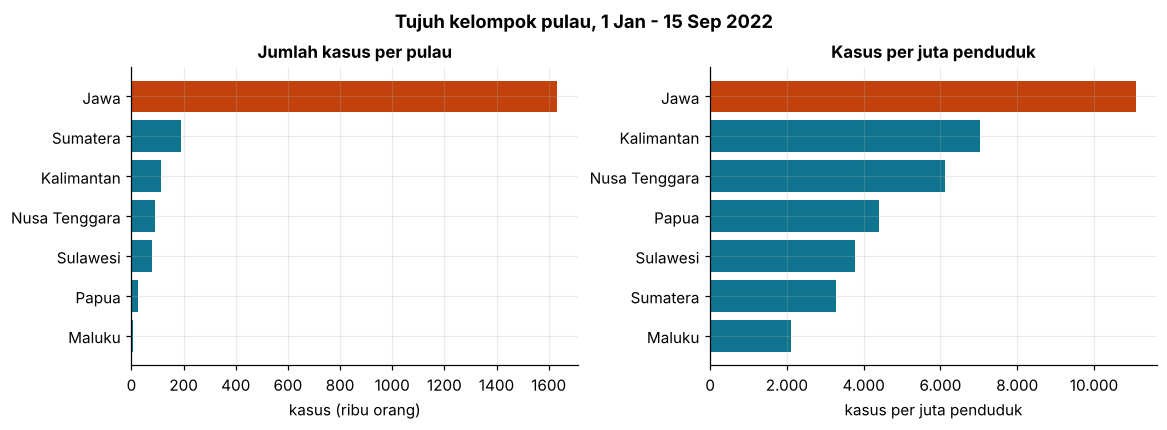

In [14]:
pulau = (prov.groupby('pulau')
             .agg(jumlah_provinsi=('provinsi', 'count'), penduduk=('penduduk', 'sum'), kasus=('kasus', 'sum'), kematian=('kematian', 'sum')))
pulau['kasus_per_juta']          = pulau['kasus'] / pulau['penduduk'] * 1_000_000
pulau['kematian_per_juta']       = pulau['kematian'] / pulau['penduduk'] * 1_000_000
pulau['kematian_per_1000_kasus'] = pulau['kematian'] / pulau['kasus'] * 1000
pulau['persen_kasus']    = pulau['kasus'] / pulau['kasus'].sum() * 100
pulau['persen_penduduk'] = pulau['penduduk'] / pulau['penduduk'].sum() * 100
pulau = pulau.sort_values('kasus_per_juta', ascending=False)

m1p = pd.read_csv(f'{PROCESSED}/covid_2022_pulau.csv', index_col=0)
assert set(pulau.index) == set(m1p.index)
for k in ['jumlah_provinsi', 'penduduk', 'kasus', 'kematian']:
    assert (pulau.loc[m1p.index, k] == m1p[k]).all(), f'{k} pulau tidak sama dengan M1'
for k in ['kasus_per_juta', 'kematian_per_juta', 'kematian_per_1000_kasus']:
    assert np.allclose(pulau.loc[m1p.index, k], m1p[k], atol=0.006), f'{k} pulau tidak sama dengan M1'
print('LOLOS: tabel pulau sama dengan M1.\n')
print(pulau.round(1).to_string())

p1 = pulau.sort_values('kasus_per_juta')
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8), layout='constrained')
p0 = pulau.sort_values('kasus')
ax[0].barh(p0.index, p0['kasus'] / 1e3, color=[SOROT if i == p0['kasus'].idxmax() else DATA for i in p0.index]); ax[0].set_xlabel('kasus (ribu orang)'); ax[0].set_title('Jumlah kasus per pulau')
ax[1].barh(p1.index, p1['kasus_per_juta'], color=[SOROT if i == p1['kasus_per_juta'].idxmax() else DATA for i in p1.index]); ax[1].set_xlabel('kasus per juta penduduk'); ax[1].set_title('Kasus per juta penduduk')
ax[1].xaxis.set_major_formatter(ribuan)
fig.suptitle('Tujuh kelompok pulau, 1 Jan - 15 Sep 2022', fontsize=12, fontweight='bold')
plt.savefig(f'{FIGURES}/p6_pulau.png', dpi=150); plt.show()

**Tafsiran 3a — jawaban sementara Pertanyaan 3.** **Jawa** paling banyak terkena, baik dalam jumlah (1.631.428 kasus = 76,4%) maupun per penduduk (11.083 per juta, tertinggi dan sekitar 1,6 kali Kalimantan di urutan kedua). Jawa memuat 55,5% penduduk, jadi porsi kasusnya jauh melebihi porsi penduduknya. Sumatera (10 provinsi, 21,8% penduduk) hanya 8,9% kasus; per juta penduduk yang terendah adalah Maluku (2.102). M1 menunjukkan Jawa **tanpa DKI Jakarta** tetap 7.951 per juta, masih tertinggi.
**Catatan metode:** `island` adalah pengelompokan dataset (Bali ∈ Nusa Tenggara; Kepulauan Riau dan Bangka Belitung ∈ Sumatera). Jumlah provinsi per kelompok tidak seimbang (Sumatera 10; Maluku dan Papua 2), dan tiap kelompok didominasi satu-dua provinsi. Dominasi Jawa tidak otomatis berarti "daerah Jawa lebih rentan": angka ini belum memperhitungkan jumlah tes, mobilitas, atau struktur umur.

### 3b. Status wilayah dan zona waktu (jumlah provinsi)

In [15]:
for k in ['special_status', 'time_zone']:
    vc = w.groupby('location')[k].first().value_counts()
    print(f'\n{k} - jumlah PROVINSI per kategori ({len(vc)} nilai unik)')
    print(pd.DataFrame({'jumlah': vc, 'persen': (vc / vc.sum() * 100).round(1)}).to_string())


special_status - jumlah PROVINSI per kategori (4 nilai unik)
                         jumlah  persen
special_status                         
Tidak ada status khusus      29    85.3
Daerah Khusus                 3     8.8
Daerah Khusus Ibu Kota        1     2.9
Daerah Istimewa               1     2.9

time_zone - jumlah PROVINSI per kategori (3 nilai unik)
           jumlah  persen
time_zone                
UTC+07:00      18    52.9
UTC+08:00      12    35.3
UTC+09:00       4    11.8


**Tafsiran 3b.** 29 dari 34 provinsi (85,3%) tidak punya status khusus, sehingga kategori lainnya hanya terdiri dari 1–3 provinsi (Daerah Khusus 3, DKI 1, DI Yogyakarta 1). Statistik per kategori tidak dapat dipercaya dan **status khusus tidak dipakai sebagai pembanding**. Zona waktu: 18 WIB, 12 WITA, 4 WIT; tidak berkaitan langsung dengan pertanyaan kami.

### 3c. Tingkat keparahan harian (`kelas_kasus`) dan ritme mingguan (`hari`)

kelas_kasus (binning new_cases_per_million: <=1, 1-10, 10-30, >30 per hari), jumlah baris provinsi-hari:
               jumlah  persen
kelas_kasus                  
Sangat rendah    3526    40.2
Rendah           2835    32.3
Sedang            956    10.9
Tinggi           1453    16.6

kasus baru per provinsi-hari menurut hari dalam pekan:
      mean  median
Sen  170.4     5.0
Sel  251.9    10.0
Rab  282.5    10.0
Kam  271.3    11.0
Jum  254.3     9.0
Sab  257.5     8.0
Min  216.2     6.0


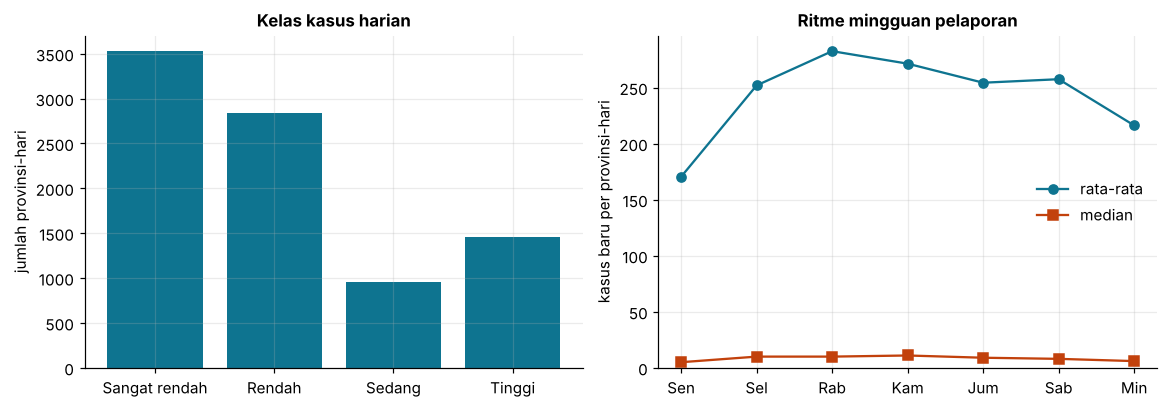

In [16]:
urut_kelas = ['Sangat rendah', 'Rendah', 'Sedang', 'Tinggi']
kk = w['kelas_kasus'].value_counts().reindex(urut_kelas)
print('kelas_kasus (binning new_cases_per_million: <=1, 1-10, 10-30, >30 per hari), jumlah baris provinsi-hari:')
print(pd.DataFrame({'jumlah': kk, 'persen': (kk / kk.sum() * 100).round(1)}).to_string())

urut_hari = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
lab = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
hh = w.groupby('hari')['new_cases'].agg(['mean', 'median']).reindex(urut_hari)
hh.index = lab
print('\nkasus baru per provinsi-hari menurut hari dalam pekan:'); print(hh.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
ax[0].bar(kk.index, kk.values, color=DATA); ax[0].set_ylabel('jumlah provinsi-hari'); ax[0].set_title('Kelas kasus harian')
ax[1].plot(hh.index, hh['mean'], marker='o', color=DATA, label='rata-rata'); ax[1].plot(hh.index, hh['median'], marker='s', color=SOROT, label='median')
ax[1].set_ylabel('kasus baru per provinsi-hari'); ax[1].set_title('Ritme mingguan pelaporan'); ax[1].legend(frameon=False); ax[1].set_ylim(0)
plt.savefig(f'{FIGURES}/p6_kategorikal.png', dpi=150); plt.show()

**Tafsiran 3c.** Kelas keparahan **tidak seimbang**: 40,2% provinsi-hari berkelas Sangat rendah dan 32,3% Rendah, sedangkan Tinggi hanya 16,6% (Sedang 10,9%). Kelas Tinggi (>30 kasus per juta per hari) sangat terkonsentrasi di gelombang awal tahun: 83% baris Tinggi jatuh pada Februari–Maret 2022. Rata-rata kasus **berbeda menurut hari dalam pekan**: Senin paling rendah (170,4) dan Rabu paling tinggi (282,5), selisih sekitar 40%; mediannya Senin 5 vs Kamis 11. Pola ini sejalan dengan ritme pelaporan (kasus akhir pekan dilaporkan kemudian), **dugaan yang belum diuji** dan tidak boleh dibaca sebagai pola penularan. Inilah alasan `02_cleaning.ipynb` membuat `kasus_rata7`: rata-rata 7 hari meredam pola mingguan pada analisis deret waktu.

## 4. Ringkasan temuan univariat

| Variabel | Bentuk distribusi | Pemusatan yang dipakai | Outlier | Catatan untuk analisis berikutnya |
|----------|-------------------|------------------------|---------|-----------------------------------|
| `new_cases` harian | Menjulur kanan ekstrem (skew 8,48), 17,8% nol | Median (8) | 17,3% (IQR), sah: gelombang Februari | Skala log; total jendela didominasi Februari (≈57%) |
| `new_deaths` harian | Zero-inflated (70,4% nol), skew 8,78 | Tidak dipakai harian | 12,9% (artefak IQR sempit) | Pakai agregat per provinsi |
| `kasus` (n = 34) | Menjulur kanan (skew 3,09) | Median (17.097) | 5 provinsi Jawa, sah | Jakarta + Jawa Barat = 47% kasus |
| `kasus_per_juta` (n = 34) | Menjulur kanan (skew 3,63) | Median (4.233) | Jakarta, Banten, DIY | Ukuran Q1 M1; urutan bawah berbeda dari jumlah |
| `kepadatan` (n = 34) | Menjulur kanan (skew 5,67) | Median (102) | 7 provinsi; Jakarta ekstrem | **Leverage Jakarta**: uji dengan/tanpa Jakarta |
| `kematian_per_1000_kasus` (n = 34) | Hampir simetris (skew 1,15) | Mean ≈ median ≈ 9,5 | Aceh (28,0) | Rasio terhadap kasus terdeteksi; waspadai pengujian dan kasus kecil |
| `island` (7 kategori) | Tak seimbang (Sumatera 10; Maluku, Papua 2) | — | — | Tabel silang punya sel kecil |
| `kelas_kasus`, `hari` | Kelas sangat tak seimbang; ritme mingguan | — | — | Pakai `kasus_rata7` untuk deret waktu |

## 5. Keluaran untuk perbandingan Python vs KNIME (M4, Pertemuan 11)

Pertemuan 11 menunjukkan bahwa **angka statistik sering tidak sama antar-alat** karena setelan bawaan berbeda, bukan karena salah satunya rusak. Berikut yang perlu diperiksa saat membandingkan workflow KNIME dengan hasil di atas. Kolom *efek* dihitung di sini pada data kami, jadi besar-kecilnya selisih sudah dapat diperkirakan sebelum membuka KNIME.

In [17]:
ref = pd.DataFrame(STAT).T
efek = pd.DataFrame({
    'std ddof=1 (sampel)': ref['std_ddof1'], 'std ddof=0 (populasi)': ref['std_ddof0'],
    'selisih std (%)': (ref['std_ddof0'] / ref['std_ddof1'] - 1) * 100,
    'skew pandas (terkoreksi)': ref['skew_pandas'], 'skew SciPy (tak terkoreksi)': ref['skew_scipy'],
    'selisih skew (%)': (ref['skew_scipy'] / ref['skew_pandas'] - 1) * 100,
    'kurt pandas': ref['kurt_pandas'], 'kurt SciPy': ref['kurt_scipy']})
print(efek.round(2).to_string())

# Kuartil: beberapa cara hitung memberi Q1/Q3 berbeda pada n kecil (provinsi, n = 34)
x = prov['kasus'].to_numpy(float)
print('\nQ1 dan Q3 kasus per provinsi menurut cara hitung kuartil (n = 34):')
for m in ['linear', 'lower', 'higher', 'midpoint', 'nearest', 'weibull', 'hazen']:
    print(f'  {m:9s} Q1 = {np.quantile(x, .25, method=m):10,.2f}   Q3 = {np.quantile(x, .75, method=m):10,.2f}')

                                    std ddof=1 (sampel)  std ddof=0 (populasi)  selisih std (%)  skew pandas (terkoreksi)  skew SciPy (tak terkoreksi)  selisih skew (%)  kurt pandas  kurt SciPy
new_cases (harian)                              1013.24                1013.19            -0.01                      8.48                         8.48             -0.02        89.02       88.97
new_deaths (harian)                                5.99                   5.99            -0.01                      8.78                         8.77             -0.02       106.92      106.86
kasus (provinsi)                              123616.73              121785.27            -1.48                      3.09                         2.95             -4.47         9.50        7.99
kasus_per_juta (provinsi)                       9014.17                8880.62            -1.48                      3.63                         3.47             -4.47        16.16       13.71
kepadatan (provinsi)          

**Daftar setelan yang harus disamakan atau dicatat saat membandingkan dengan KNIME**

| Setelan | Python (notebook ini) | Yang diperiksa di KNIME | Besar efek pada data kami |
|---|---|---|---|
| Simpangan baku | `ddof=1` (sampel); `np.std` bawaan memakai `ddof=0` | Apakah node memakai pembagi n atau n−1 | Kecil pada n = 8.770, ±1,5% pada n = 34 (tabel di atas) |
| Kuartil/IQR | Interpolasi linear | Metode kuartil pada node Statistics/Box Plot | Berbeda pada n = 34 (daftar metode di atas), sehingga **jumlah outlier IQR dapat bergeser** |
| Skewness/kurtosis | pandas (terkoreksi) dan SciPy (tak terkoreksi) | Rumus yang dipakai node | Kecil pada n = 8.770, **besar pada n = 34** (skewness `kasus`: 3,09 vs 2,95) |
| Nilai nol dan kosong | `persen_nol` dilaporkan; `NaN` dibuang per kolom | Apakah nol dan *missing* diperlakukan sama | `kasus_rata7`, `growth_factor` punya `NaN` yang sah |
| Penyaringan jendela | `1 Jan–15 Sep 2022` inklusif → 8.770 baris | Row Filter pada `date` | Harus tepat 8.770 baris, jumlah `new_cases` 2.134.660 |
| Pembulatan | `round(2)` hanya saat menampilkan | Format tampilan vs nilai tersimpan | Perbedaan di desimal ke-3+ bukan selisih nyata |

**Catatan:** tabel ini menyebut hal yang perlu *diperiksa*; belum membuktikan apa pun tentang KNIME. Setelan bawaan KNIME dicatat dari hasil eksekusi workflow tim sendiri, bukan dari daftar umum.

In [18]:
ref.round(4).to_csv(f'{REPORTS}/p6_statistik_deskriptif.csv', index_label='variabel')
efek.round(4).to_csv(f'{REPORTS}/p6_efek_setelan.csv', index_label='variabel')
print('Tersimpan di reports/:', sorted(f for f in os.listdir(REPORTS) if f.startswith('p6_')))
print('Tersimpan di reports/figures/:', sorted(f for f in os.listdir(FIGURES) if f.startswith('p6_')))

Tersimpan di reports/: ['p6_efek_setelan.csv', 'p6_outlier_provinsi.csv', 'p6_statistik_deskriptif.csv']
Tersimpan di reports/figures/: ['p6_kasus_harian.png', 'p6_kasus_harian_waktu.png', 'p6_kasus_per_juta.png', 'p6_kasus_provinsi.png', 'p6_kategorikal.png', 'p6_kematian_harian.png', 'p6_kematian_per1000.png', 'p6_kepadatan.png', 'p6_peringkat_provinsi.png', 'p6_pulau.png']


## Checklist sebelum mengumpulkan

- [x] Setiap variabel yang dianalisis memiliki tafsiran, bukan hanya grafik.
- [x] Bentuk distribusi dinyatakan dengan bukti dari gambar **dan** dari angka.
- [x] Pilihan mean atau median disertai alasan.
- [x] Keputusan tentang outlier dicatat beserta alasannya; tidak ada yang dibuang tanpa diperiksa.
- [x] Setiap grafik memiliki judul, label sumbu, dan satuan.
- [x] n yang dilaporkan adalah n setelah `dropna()`.
- [x] Tabel provinsi dan pulau diuji sama dengan keluaran M1; angka acuan sama dengan M2.
- [x] Statistik acuan untuk KNIME diekspor ke `reports/p6_statistik_deskriptif.csv`.
- [ ] Restart & Run All berjalan tanpa galat di komputer Anda.